# 03 — Explaining the models: SHAP vs Captum

Week 3 analysis notebook. It walks through the explainability work in the order it was done, and explains **why**
each choice was made, not just what was computed.

**How this notebook is built.** The heavy computation lives in `scripts/run_xai_*.py` (re-run them all with
`scripts/run_xai_analysis.py`). This notebook reads the artifacts those scripts saved (`reports/xai/`,
`reports/figures/xai/`), so every number here is one the scripts produced — nothing is typed in by hand — and it
re-computes one small example live to show the methods at work. Every non-obvious decision is logged in
`reports/xai_decisions_log.md` (IDs like D3.2 below point there).

Three cautions hold throughout:

* attributions describe what a **model** learned to rely on, **not** what causes someone to have a bank account;
* the model output is a **ranking score, not a calibrated probability** (class-weighted training), so attributions
  are in **logits**, where they add up;
* **Uganda** is the segment of most interest and the smallest (2,101 of 23,524 training rows).

In [1]:
# Fail loudly if the notebook runs in the wrong environment: the default Jupyter kernel launches whichever
# `python` is first on PATH, which need not be the XAI environment (requirements-xai.txt).
import sys
import importlib.util

missing = [m for m in ("captum", "shap", "torch", "xgboost") if importlib.util.find_spec(m) is None]
assert not missing, f"Run this notebook with the XAI environment; missing {missing} in {sys.executable}"

import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "config"))
from settings import load_settings

settings = load_settings()
ARTIFACTS, FIGURES = settings.xai.artifacts_dir, settings.xai.figures_dir
pd.set_option("display.precision", 3)


def load(name):
    return json.loads((ARTIFACTS / name).read_text(encoding="utf-8"))


def figure(name, width=900):
    path = FIGURES / name
    assert path.exists(), f"missing figure {name}: run scripts/run_xai_analysis.py"
    display(Image(filename=str(path), width=width))


verification, sets = load("model_verification.json"), load("sample_sets.json")
shap_summary, captum_summary = load("shap_summary.json"), load("captum_summary.json")
internals, comparison = load("internals_summary.json"), load("comparison_summary.json")
print("Loaded the saved results of every phase")

Loaded the saved results of every phase


## 1. Which models, and can we trust that they are the models we reported?

The shipped XGBoost model is loaded from `models/production/`. The PyTorch MLP from the ablation study was never
saved, so it was **retrained** with the hyperparameters every outer fold had chosen (D0.1, D2.2).

Explaining a model that does not perform like the one in the ablation report would explain something else, so
nothing was explained until both passed a **verification gate**: re-run the report's 5-fold cross-validation (same
seed, same folds) with each model's final settings, and require mean PR-AUC within ±0.02 of the reported value
(D2.1). There is no labelled hold-out of the final models: both are trained on every labelled row, and the test file
has no labels.

In [2]:
gate = pd.DataFrame({
    model: {
        "reported mean PR-AUC": verification[model]["reported_mean_pr_auc"],
        "re-run mean PR-AUC": verification[model]["mean_pr_auc"],
        "largest per-fold difference": verification[model]["max_abs_fold_diff"],
        "Uganda mean PR-AUC": verification[model]["uganda_mean_pr_auc"],
        "within ±0.02": verification[model]["within_band"],
    }
    for model in ("xgboost", "mlp")
})
gate

,xgboost,mlp
reported mean PR-AUC,0.59,0.584
re-run mean PR-AUC,0.588,0.584
largest per-fold difference,0.007,0.0
Uganda mean PR-AUC,0.544,0.542
within ±0.02,True,True


The MLP reproduces the reported folds exactly. XGBoost is within the band but not identical, because its shipped
settings were tuned on all the data, unlike the per-fold settings behind the reported number — so its re-run figure
is mildly optimistic, and is reported as such rather than as a reproduction.

## 2. Which rows, and compared with what?

Every explanation compares a respondent with a **reference**. For SHAP that is a background set; we use 200 training
rows drawn **proportionally** by country × outcome, so the base value is close to the average respondent's logit
(an equal-allocation draw would over-represent account holders and small countries; D2.5). Explanations are
computed for 1,000 stratified rows (pooled results) plus every Uganda row (Uganda results) — pooled statistics never
include the extra Uganda rows, which would over-weight Uganda about sixfold (D2.6).

In [3]:
composition = pd.DataFrame(sets["composition"]["background"]).T
composition["share with account"] = composition["Yes"] / composition.sum(axis=1)
display(composition)
print("Mean logit, all training rows vs background:", sets["composition"]["mean_logit"])

,No,Yes,share with account
Kenya,39,13,0.250
Rwanda,66,8,0.108
Tanzania,51,5,0.089
Uganda,16,2,0.111


Mean logit, all training rows vs background: {'xgboost': {'all_training_rows': -1.2095455264127646, 'background': -1.2473498943052255}, 'mlp': {'all_training_rows': -1.1622039299843716, 'background': -1.2508665722236036}}


Only 18 background rows are Ugandan, so Uganda results answer *"why does this Ugandan respondent score differently
from a typical pooled respondent"*, not from a typical Ugandan.

## 3. Task 1 — SHAP

### 3.1 A ground truth first

With only 10 raw fields there are 2¹⁰ = 1,024 coalitions, so the **exact** Shapley value can be computed by brute
force. That makes it possible to check each SHAP method against the definition instead of trusting it. The cell
below does it live for one respondent: exact interventional Shapley values for the shipped XGBoost model, and the
efficiency check (contributions + base value = the model's logit).

In [4]:
from fin_inclusion.interpretability.shapley import ExactShapleyExplainer
from fin_inclusion.interpretability.workspace import load_workspace

ws = load_workspace(settings.paths.raw_train, settings.paths.raw_test, ROOT / "models" / "production",
                    settings.xai.model_dir, settings.xai.artifacts_dir)
respondent = ws.rows(ws.sets.focus[:1])  # the first Ugandan respondent
exact = ExactShapleyExplainer(ws.xgboost, ws.background).explain(respondent)
logit = ws.xgboost.predict_logit(respondent)[0]

display(pd.DataFrame({"value": respondent.iloc[0], "contribution (logits)": exact.values[0]}))
print(f"base value {exact.base_value:+.4f} + sum of contributions {exact.values.sum():+.4f} "
      f"= {exact.base_value + exact.values.sum():+.4f}; model logit {logit:+.4f}")

,value,contribution (logits)
country,Uganda,-0.255
location_type,Rural,-0.059
cellphone_access,No,-1.004
gender_of_respondent,Female,-0.134
relationship_with_head,Head of Household,0.063
marital_status,Divorced/Seperated,-0.028
education_level,Primary education,-0.206
job_type,Other Income,0.158
household_size,5,0.049
age_of_respondent,32,0.165


base value -1.2473 + sum of contributions -1.2514 = -2.4987; model logit -2.4987


Against this ground truth, on 50 rows (D3.2): KernelSHAP with every coalition enumerated is identical to floating-point
precision and converges to it as samples increase; **grouped TreeSHAP is close but not identical**. TreeSHAP's
players are the 40 encoded columns, and summing them is a different game from the 10 raw fields whenever trees
combine several columns of one category — a unit test confirms the two coincide when trees have depth 1.

In [5]:
oracle = shap_summary["oracle"]
convergence = pd.DataFrame({m: {n: e["mean_abs_error"] for n, e in oracle[m]["kernel_shap_error_by_nsamples"].items()}
                            for m in ("xgboost", "mlp")})
display(convergence.rename_axis("KernelSHAP coalitions sampled").style.format("{:.2e}"))
tree = oracle["xgboost"]["tree_shap_grouped_vs_oracle"]
print(f"Grouped TreeSHAP vs exact: mean |gap| {tree['mean_abs_error']:.4f} logits "
      f"({tree['relative_mean_abs_error']:.1%} of the mean attribution), same top field on "
      f"{tree['same_top_feature_share']:.0%} of rows")
print("(20 sampled coalitions are too few for 10 fields: the regression is singular, so that row is meaningless.)")

,xgboost,mlp
KernelSHAP coalitions sampled,,
20,4.01e+12,4.77e+12
50,1.62e-02,3.01e-02
100,1.00e-02,1.93e-02
200,5.55e-03,1.08e-02
500,3.02e-03,6.14e-03
1022 (all coalitions),3.78e-16,7.23e-09


Grouped TreeSHAP vs exact: mean |gap| 0.0042 logits (2.1% of the mean attribution), same top field on 100% of rows
(20 sampled coalitions are too few for 10 fields: the regression is singular, so that row is meaningless.)


### 3.2 Global importance — pooled and Uganda

Global importance is the mean |attribution| per field, with 95% bootstrap intervals over respondents (D1.7).

pooled                         uganda                  \
                        share mean_abs ci_low ci_high  share mean_abs ci_low   
cellphone_access        0.269    0.567  0.547   0.587  0.253    0.541  0.528   
education_level         0.193    0.406  0.386   0.427  0.193    0.414  0.401   
country                 0.137    0.288  0.275   0.301  0.187    0.401  0.393   
age_of_respondent       0.109    0.228  0.216   0.243  0.108    0.230  0.222   
job_type                0.093    0.196  0.184   0.209  0.074    0.158  0.152   
gender_of_respondent    0.073    0.153  0.150   0.156  0.060    0.129  0.127   
location_type           0.053    0.112  0.106   0.117  0.064    0.136  0.132   
relationship_with_head  0.039    0.083  0.081   0.085  0.035    0.074  0.073   
marital_status          0.021    0.043  0.042   0.045  0.011    0.024  0.023   
household_size          0.014    0.029  0.027   0.030  0.015    0.032  0.030   

                                
                       ci_high  
cellphone_access         0.553  
education_level          0.427  
country                  0.407  
age_of_respondent        0.239  
job_type                 0.165  
gender_of_respondent     0.130  
location_type            0.141  
relationship_with_head   0.075  
marital_status           0.025  
household_size           0.034

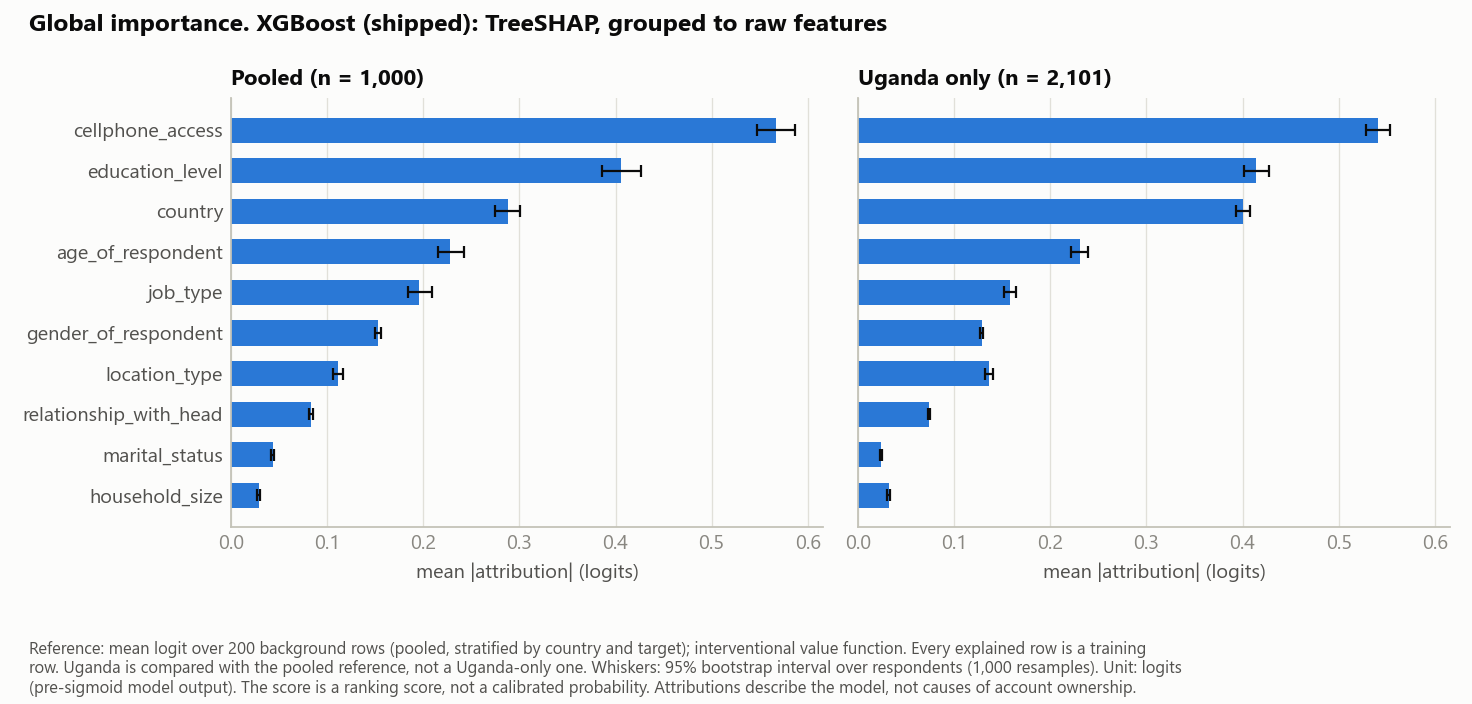

In [6]:
importance = pd.concat({
    sample: pd.DataFrame(block["features"]).T[["share", "mean_abs", "ci_low", "ci_high"]]
    for sample, block in shap_summary["global_importance"]["tree_shap__xgboost"].items()
}, axis=1).sort_values(("pooled", "share"), ascending=False)
display(importance)
figure("shap_global_importance__xgboost.png")

Phone access, education and country dominate for both models — the three the project plan expected, found here by
rank rather than assumed (D3.7). For Uganda, country's share rises; part of that is built in, since every Ugandan has
the same country while the pooled reference mostly does not.

The beeswarm shows the spread behind each average; multi-level categories are grey because shading them by an
arbitrary code would imply an order that does not exist (D3.8).

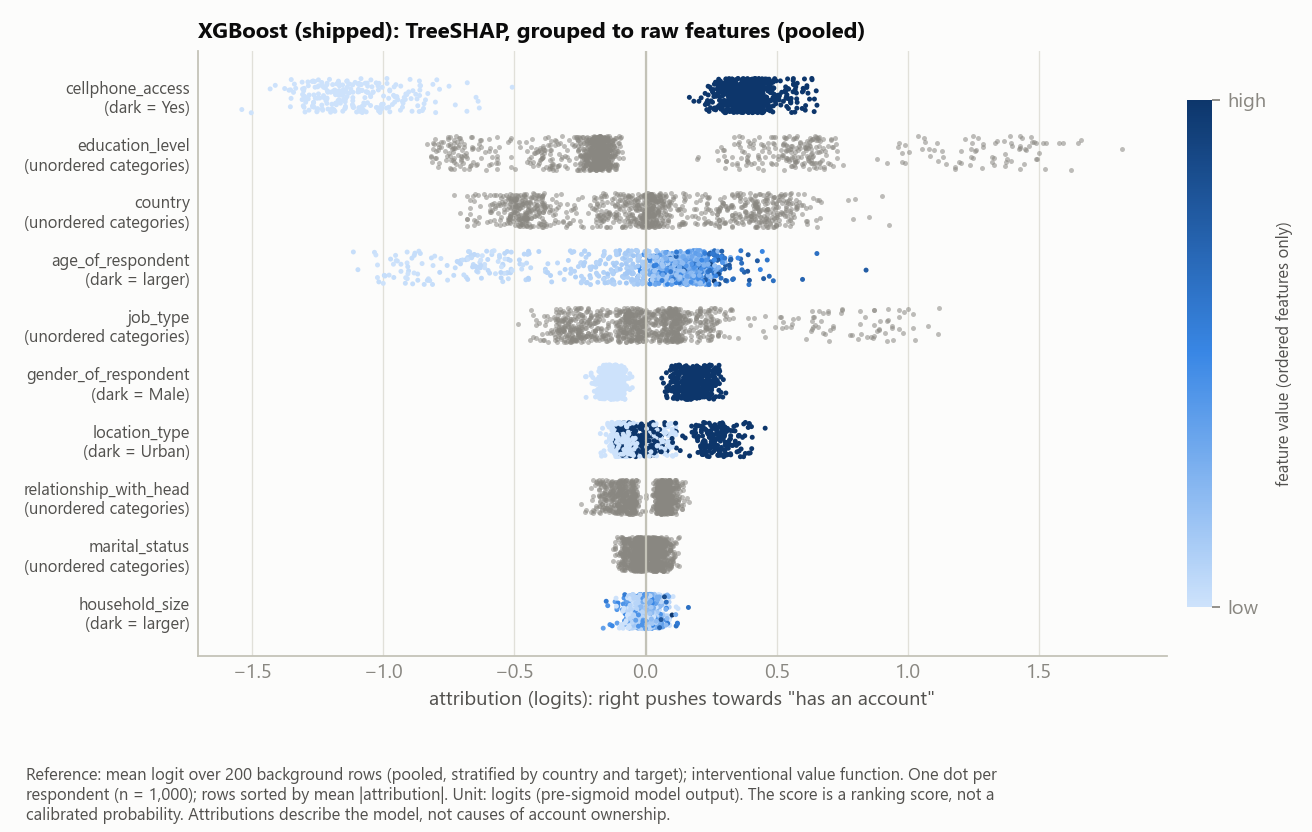

In [7]:
figure("shap_beeswarm__xgboost__pooled.png")

### 3.3 Local explanations

Five respondents chosen **by rule, not by how their explanation looks** (D3.6): the most confident true positive and
true negative, the most confident false negative and false positive, and the Ugandan closest to Uganda's median
score. The same five rows are explained for both models.

,row,country,has account,XGBoost score,MLP score,rule
confident_tp,946,Kenya,True,0.925,0.979,"has an account, predicted Yes: the highest sco..."
confident_tn,17886,Tanzania,False,0.028,0.004,"no account, predicted No: the lowest score amo..."
false_negative,18896,Tanzania,True,0.088,0.025,"has an account, predicted No: the lowest score..."
false_positive,16210,Tanzania,False,0.88,0.959,"no account, predicted Yes: the highest score a..."
focus_typical,22829,Uganda,False,0.167,0.144,focus-country row whose score is closest to th...


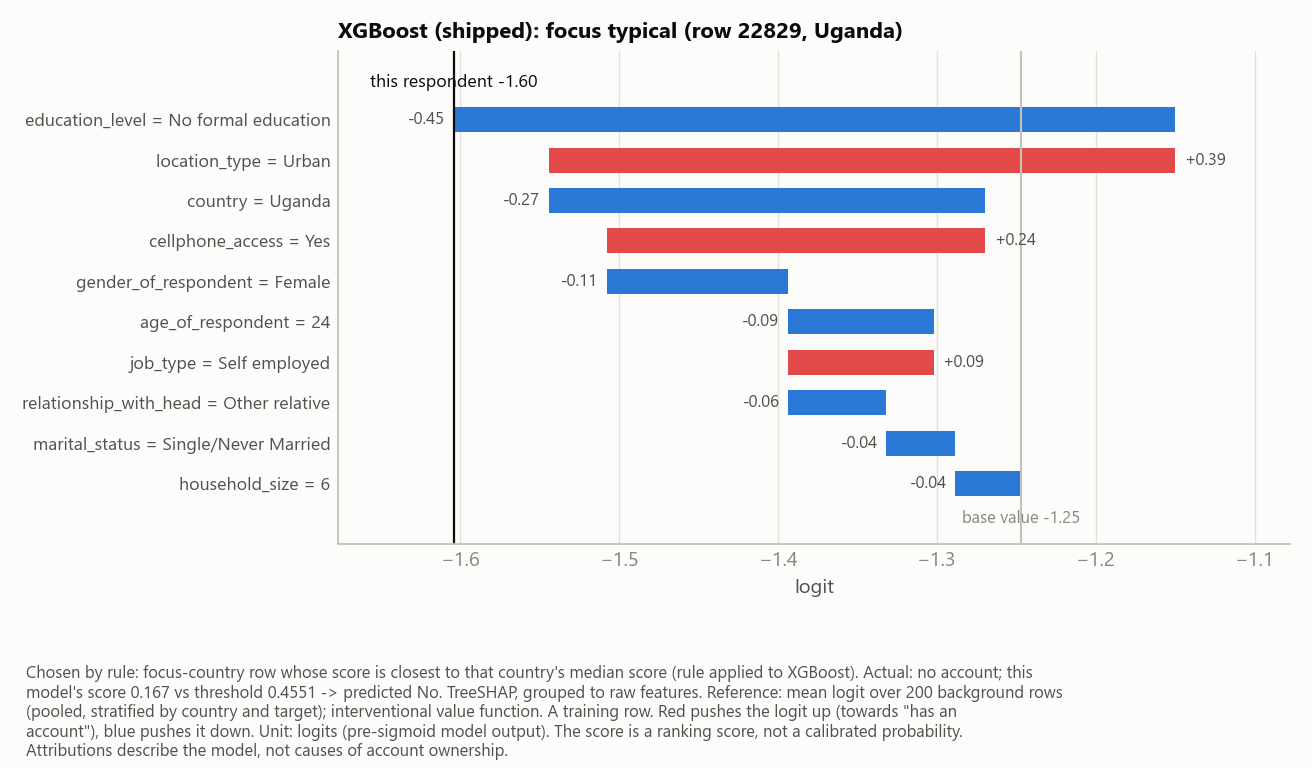

In [8]:
local = pd.DataFrame({
    name: {"row": e["row"], "country": e["country"], "has account": e["has_account"],
           "XGBoost score": e["xgboost"]["score"], "MLP score": e["mlp"]["score"], "rule": e["rule"]}
    for name, e in shap_summary["local_examples"].items()
}).T
display(local)
figure("shap_waterfall__xgboost__focus_typical.png", width=760)

### 3.4 Dependence plots

The top three fields by importance, by rule. Vertical spread at one answer is interaction with other fields: the same
answer is worth different amounts for different people.

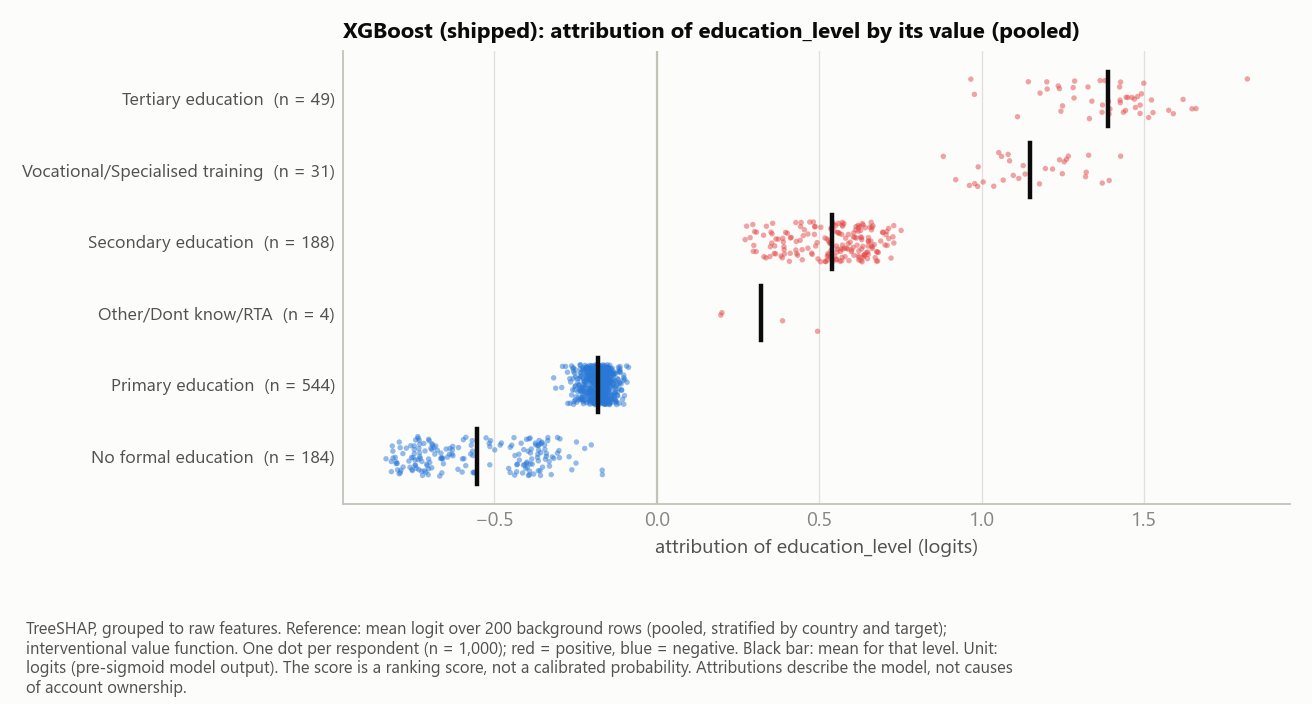

In [9]:
figure("shap_dependence__xgboost__education_level.png", width=760)

## 4. Task 2 — Captum

Captum's methods compare a respondent with **one baseline point**, not a background set. Two baselines are used
because the answer depends on the choice and that dependence is itself a result (D4.1): *modal* (every answer at its
most common value) and *unknown* (every category one the model never saw). Neither is a typical respondent.

In [10]:
baselines = pd.DataFrame({k: captum_summary["baselines"][k]["logit"] for k in ("modal", "unknown")})
baselines["mean training logit"] = pd.Series(captum_summary["baselines"]["mean_training_logit"])
baselines

,modal,unknown,mean training logit
xgboost,-0.581,-0.687,-1.210
mlp,-0.079,0.660,-1.162


**Integrated Gradients** needs a continuous path, but category indices cannot be interpolated, so the path runs
between the MLP's **embedding vectors** (LayerIntegratedGradients on each embedding layer, plus the scaled numerics;
D4.2). The number of integration steps was chosen by a rule fixed in advance — the smallest count with every
convergence delta within 0.01 logits on the 50 oracle rows — and the full-run deltas are reported as found (D4.3).

In [11]:
steps = captum_summary["integrated_gradients"]["n_steps"]
print("chosen n_steps:", steps["chosen"])
display(pd.DataFrame({k: {n: v["max_abs_delta"] for n, v in by.items()}
                      for k, by in steps["by_baseline"].items()}).rename_axis("n_steps"))
display(pd.DataFrame(captum_summary["integrated_gradients"]["full_run"]).T[["max_abs_delta", "share_rows_within_target"]])

chosen n_steps: 256


,unknown,modal
n_steps,,
32,0.038,0.076
64,0.033,0.037
128,0.012,0.022
256,0.006,0.007
512,0.003,0.004
1024,0.002,0.003


,max_abs_delta,share_rows_within_target
unknown,0.01,1.0
modal,0.014,0.996


**Feature Ablation** resets one field at a time to the baseline. It removes each field *alone*, so its contributions
do not add up — by design (D4.4).

The key Captum result: switching the baseline barely changes which fields matter **overall**, but changes **individual**
explanations a lot (D4.5).

,global Spearman,per-respondent Spearman (median),same top field
method,,,
integrated_gradients__mlp,0.770,0.273,0.494
feature_ablation__mlp,0.915,0.297,0.403
feature_ablation__xgboost,0.903,0.176,0.474


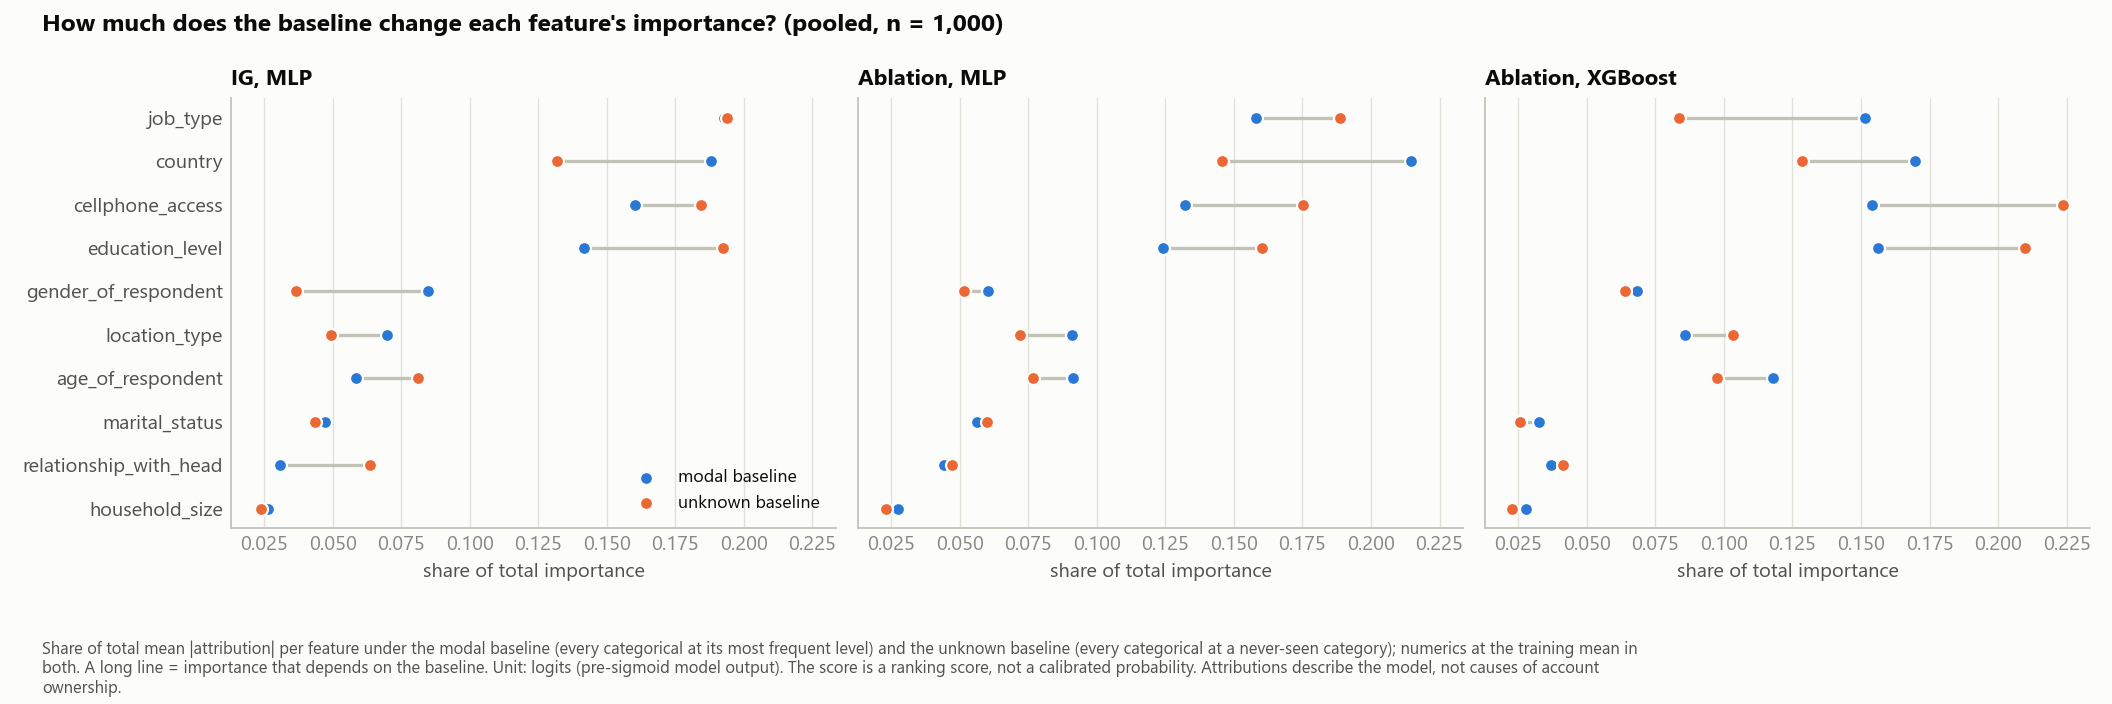

In [12]:
rows = []
for label, by_sample in captum_summary["baseline_sensitivity"].items():
    a = by_sample["pooled"]["unknown_vs_modal"]
    rows.append({"method": label, "global Spearman": a["global"]["spearman"],
                 "per-respondent Spearman (median)": a["instance_spearman"]["median"],
                 "same top field": a["same_top_feature_share"]})
display(pd.DataFrame(rows).set_index("method"))
figure("captum_baseline_sensitivity.png")

**Layer attribution** (LayerConductance, LayerGradientXActivation) shows how the MLP's computation is spread over its
hidden units. Hidden units have no meaning of their own: this describes the network's mechanics, not respondents (D4.6).

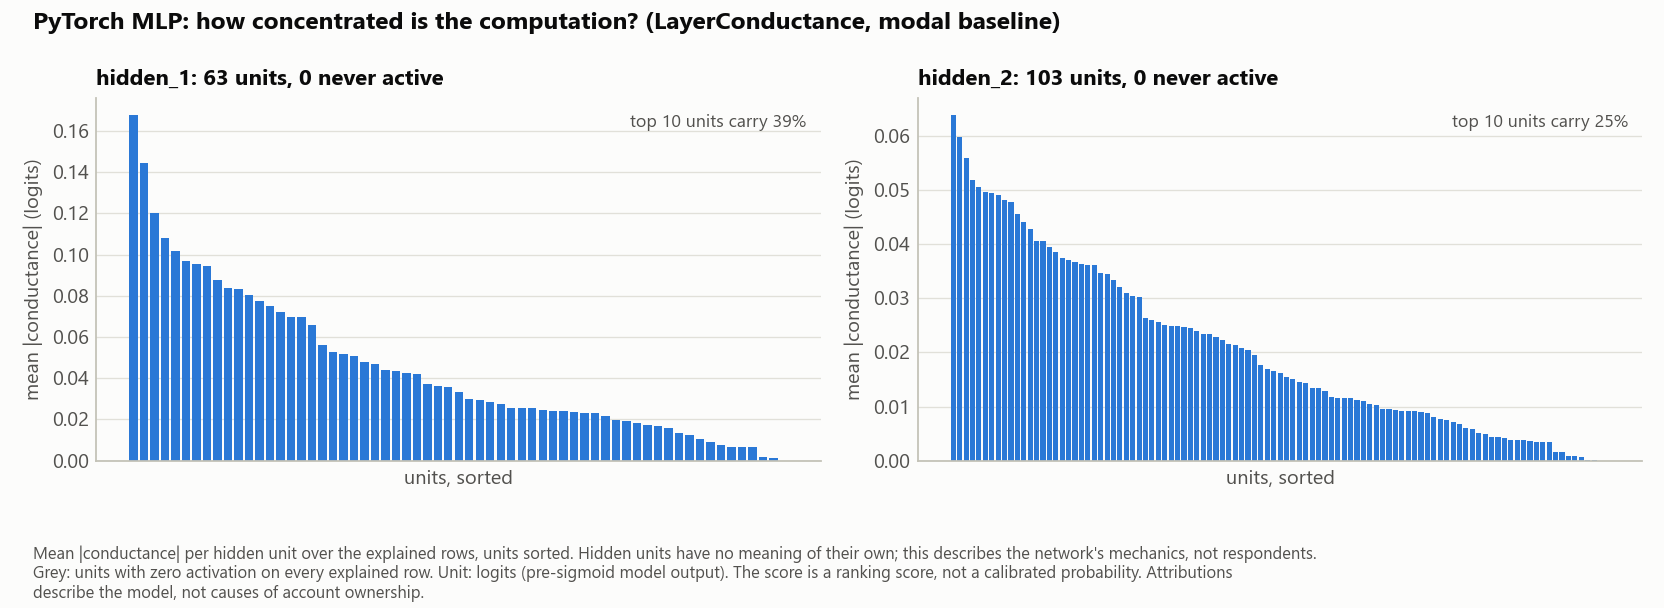

In [13]:
figure("captum_hidden_units__mlp.png")

## 5. Task 3 — Visualising internals

**Attention maps: not applicable.** Neither model has an attention mechanism, so none is drawn (D5.1). The substitutes
are real internals: every method on one scale, attribution heatmaps, the MLP's learned embeddings, and exact Shapley
interaction values.

Attention maps: not applicable. Neither model has an attention mechanism (XGBoost is a tree ensemble; the PyTorch model is an MLP over category embeddings), so no attention map exists and none is drawn. Substitutes: 2-D projections of the learned category embeddings, and exact Shapley interaction values.


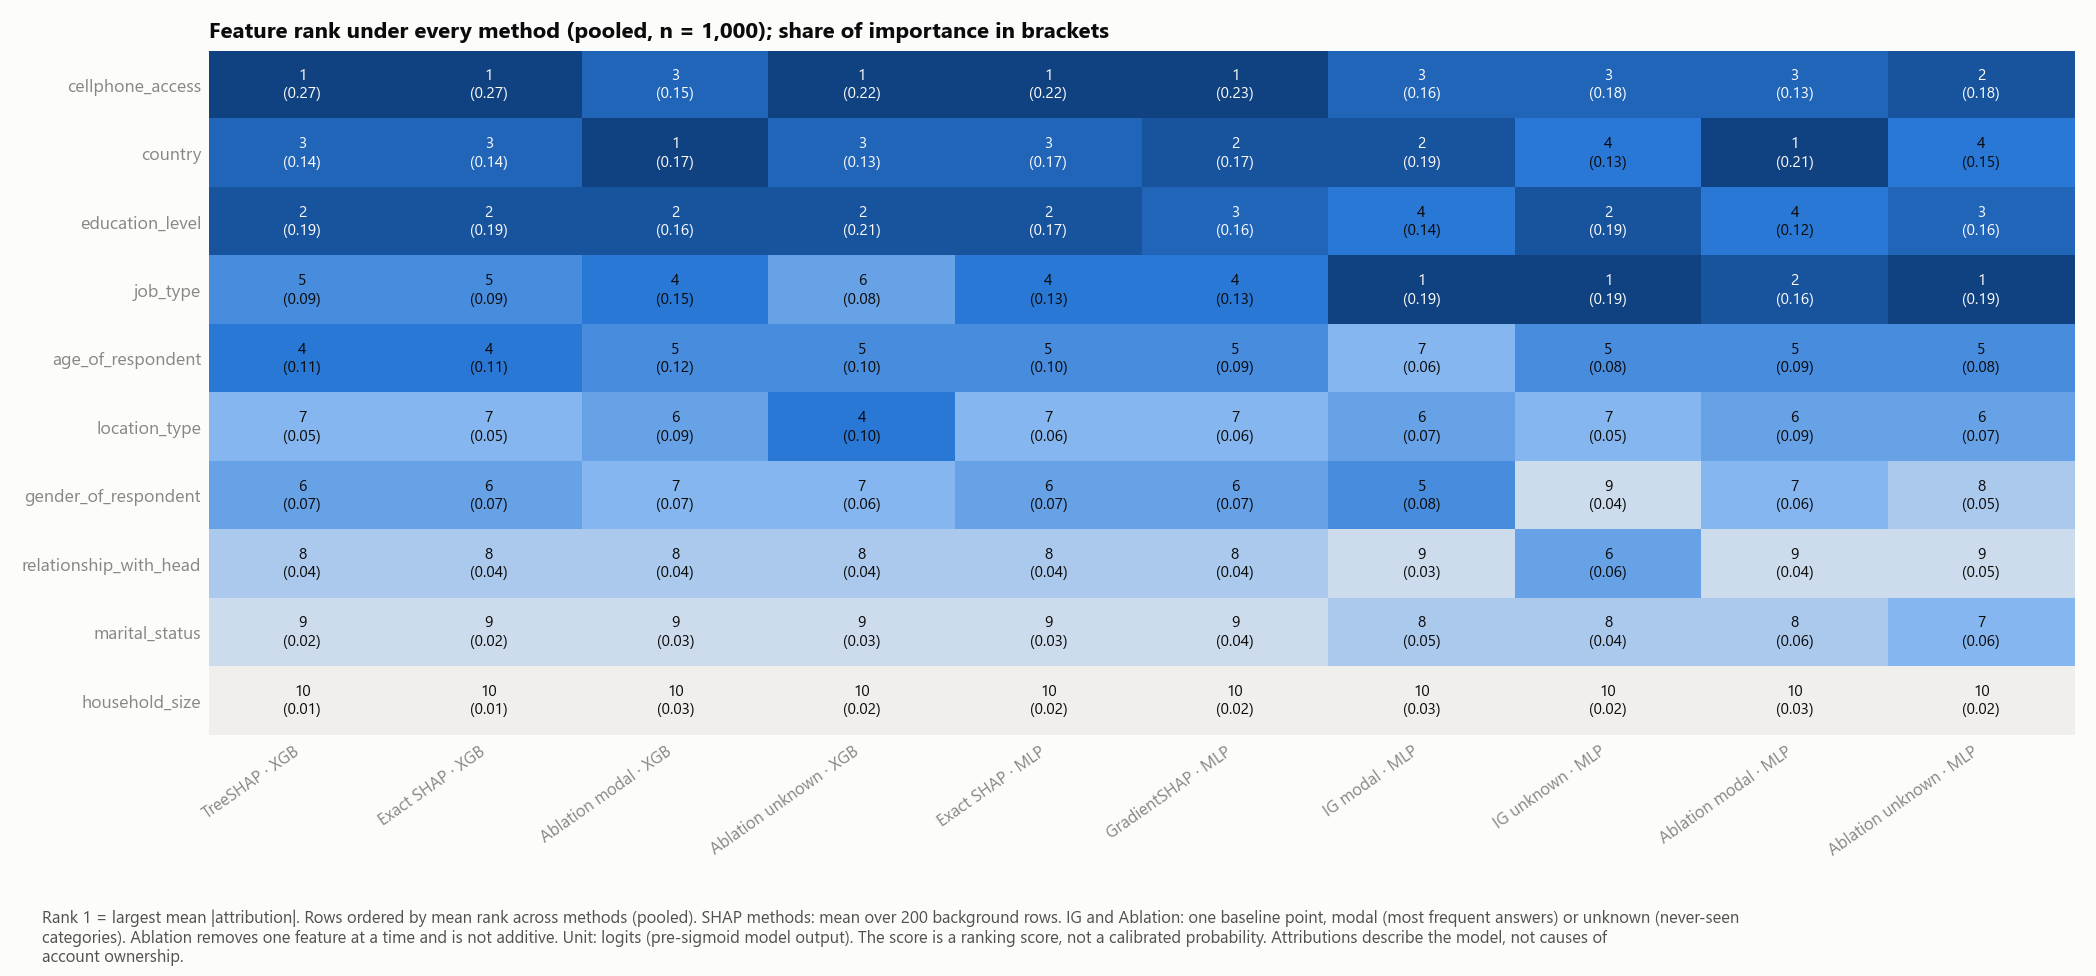

In [14]:
print(internals["attention_maps"])
figure("internals_rank_table__pooled.png")

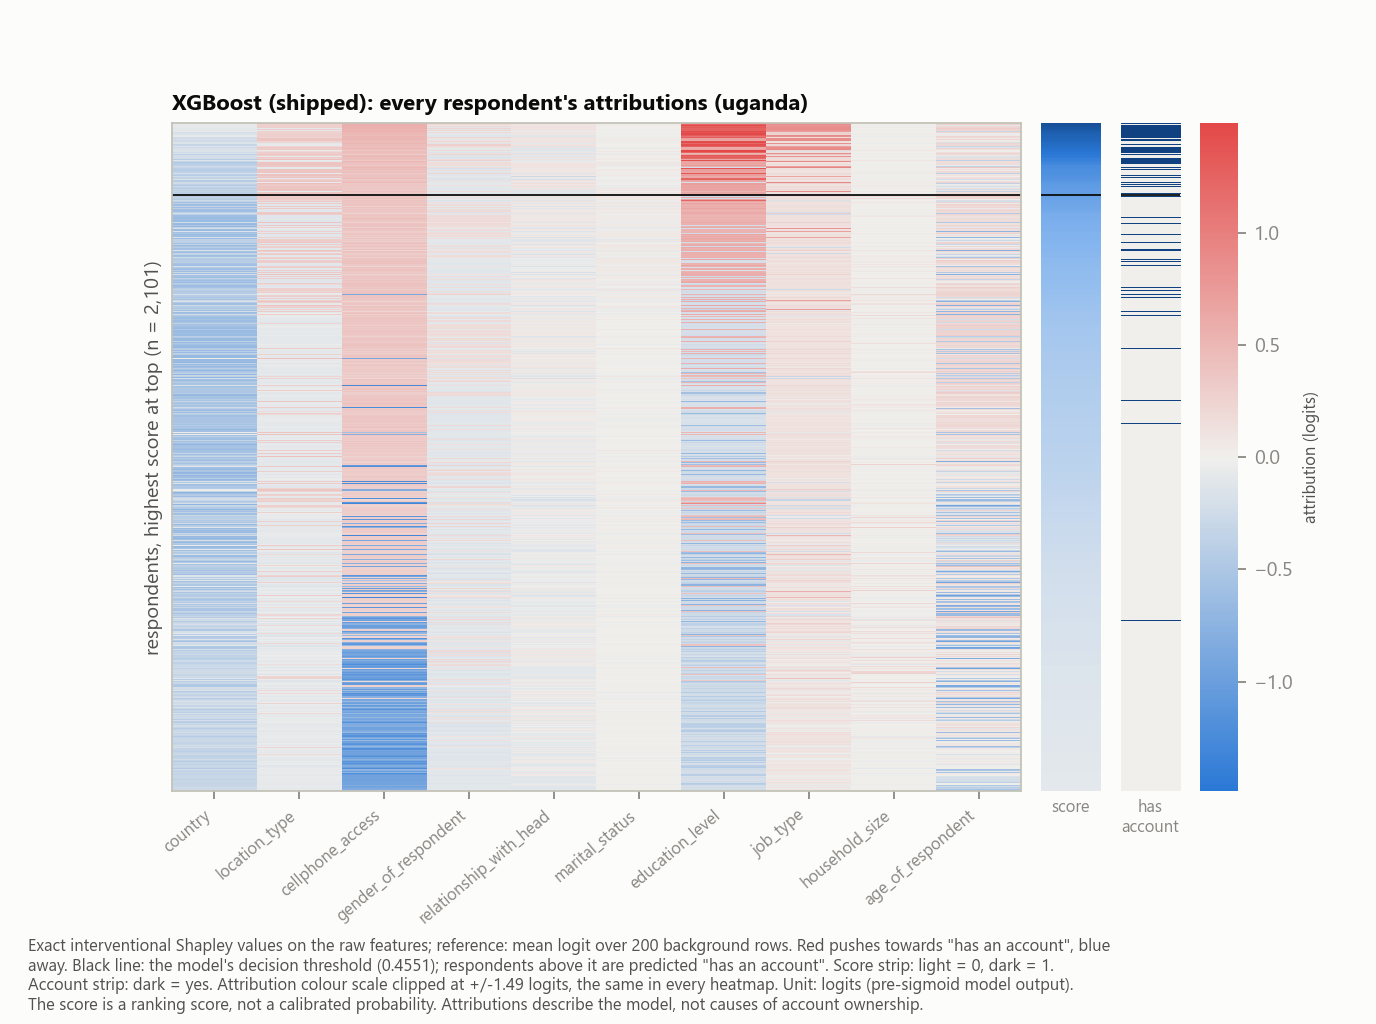

In [15]:
figure("internals_attribution_heatmap__xgboost__uganda.png", width=760)

Strongest interacting pairs: {'xgboost': [(['country', 'location_type'], 0.091), (['country', 'job_type'], 0.058), (['cellphone_access', 'education_level'], 0.05)], 'mlp': [(['country', 'location_type'], 0.198), (['country', 'job_type'], 0.1), (['country', 'marital_status'], 0.069)]}
Share of |attribution| in pairwise interactions: {'xgboost': 0.416, 'mlp': 0.454}


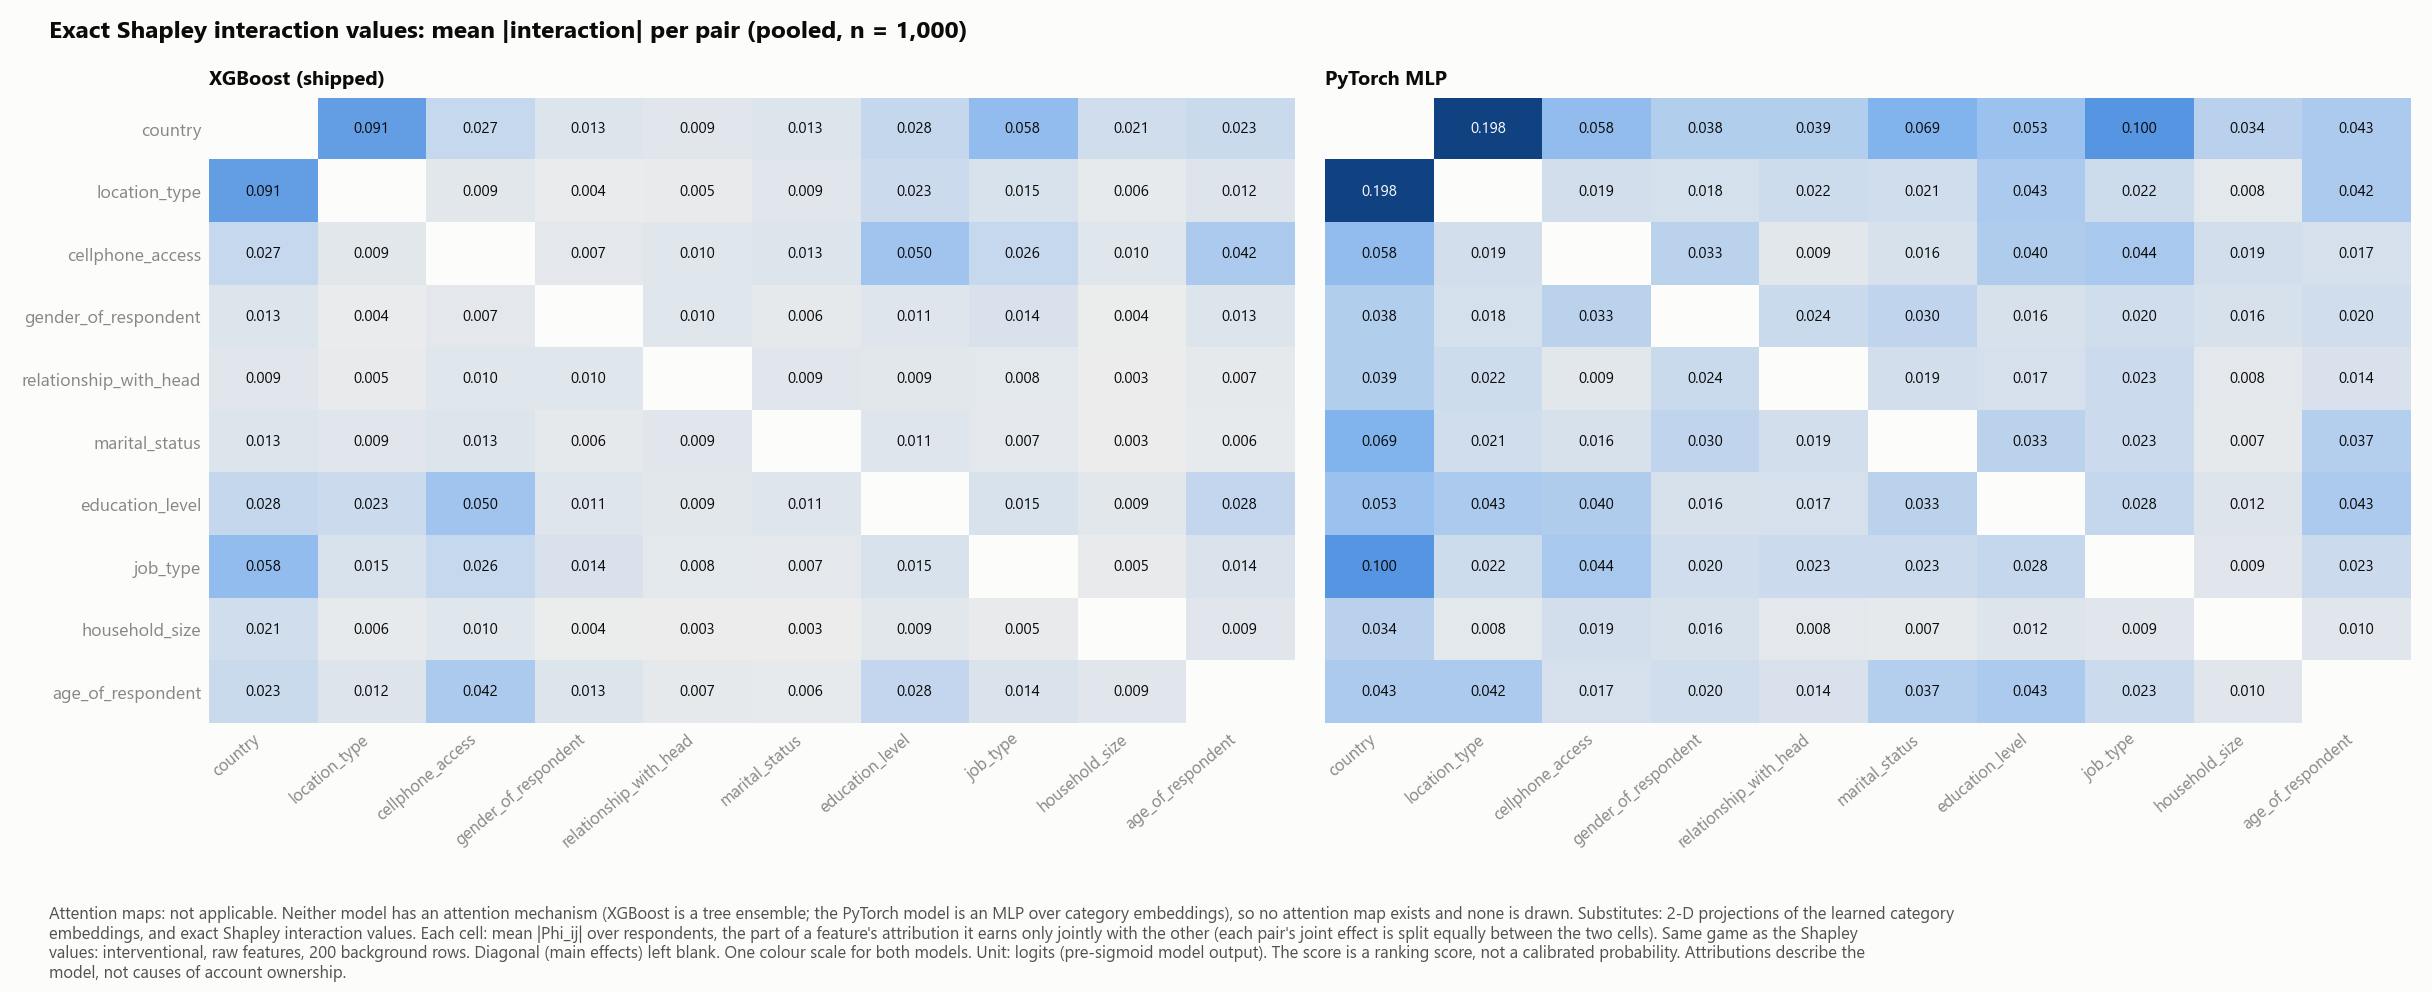

In [16]:
pairs = {m: [(p["pair"], round(p["mean_abs_each_half"], 3)) for p in internals["interactions"][m]["top_pairs_mean_abs"][:3]]
         for m in ("xgboost", "mlp")}
print("Strongest interacting pairs:", pairs)
print("Share of |attribution| in pairwise interactions:",
      {m: round(internals["interactions"][m]["share_of_abs_attribution_in_interactions"], 3) for m in ("xgboost", "mlp")})
figure("internals_shapley_interactions.png")

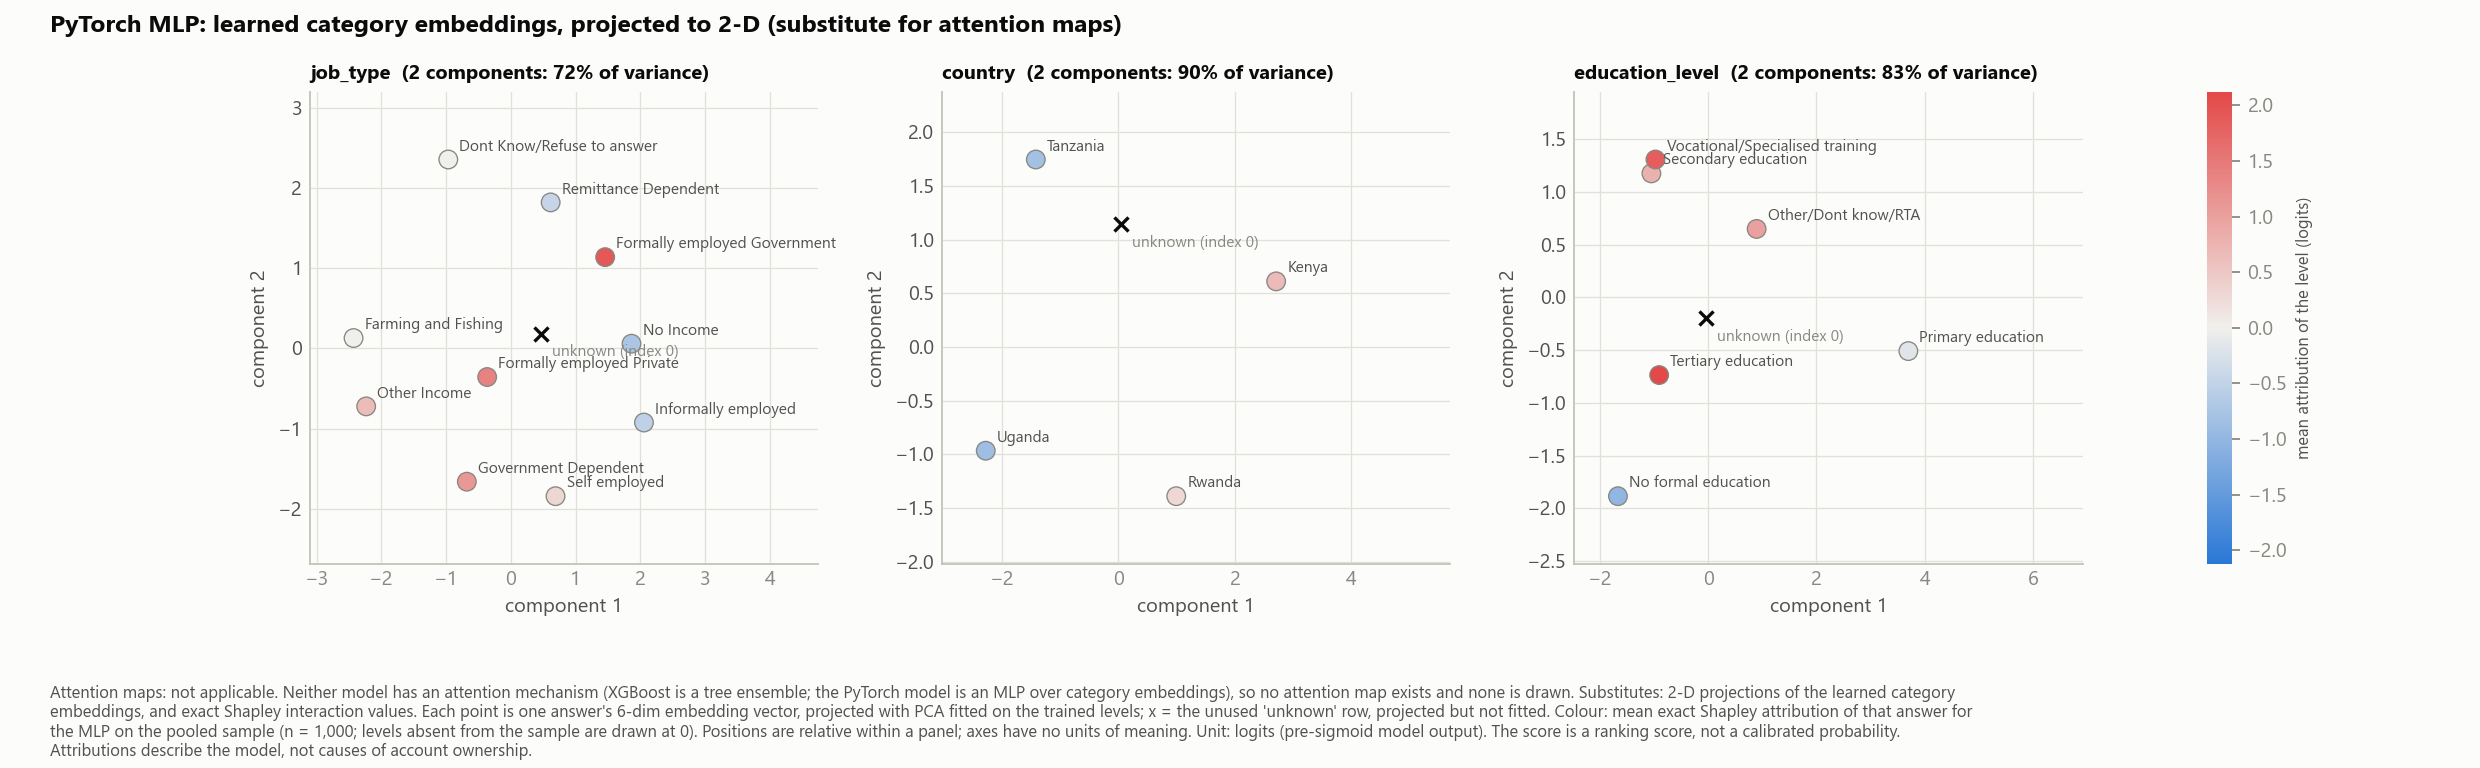

In [17]:
figure("internals_embedding_projection__mlp.png")

## 6. Task 4 — SHAP vs Captum

Two experiments keep **method** effects apart from **model** effects: **A** compares methods on the same model (the
MLP); **B** compares the two models. To separate the *reference* from the *method*, exact Shapley values were also
computed against the same baseline point IG and Ablation use (D6.1): row R1 changes only the reference, M1–M4 change
only the method.

Per-respondent agreement is measured with the shared exact zeros excluded: with one baseline point, a field on which a
respondent equals the baseline gets exactly zero from IG, Ablation and point-Shapley alike, whatever the model, which
inflates their apparent agreement (D6.2).

,comparison,global ρ,per-respondent ρ,ci low,ci high,same top,same sign
id,,,,,,,
A1,Exact SHAP vs IG (modal),0.842,0.338,0.317,0.356,0.561,0.797
A2,Exact SHAP vs IG (unknown),0.830,0.648,0.636,0.673,0.450,0.845
A3,Exact SHAP vs Ablation (modal),0.879,0.362,0.330,0.387,0.512,0.849
A4,Exact SHAP vs Ablation (unknown),0.867,0.667,0.648,0.685,0.470,0.829
A5,IG vs Ablation (both modal),0.939,0.821,0.800,0.829,0.717,0.845
A6,Exact SHAP vs GradientSHAP,0.988,0.952,0.952,0.952,0.923,0.960
R1,SHAP: background vs modal point (reference only),0.891,0.369,0.343,0.399,0.603,0.834
M1,SHAP vs IG at the modal point (method only),0.976,0.943,0.943,0.943,0.900,0.915
M2,SHAP vs Ablation at the modal point (method only),0.927,0.829,0.829,0.857,0.738,0.886


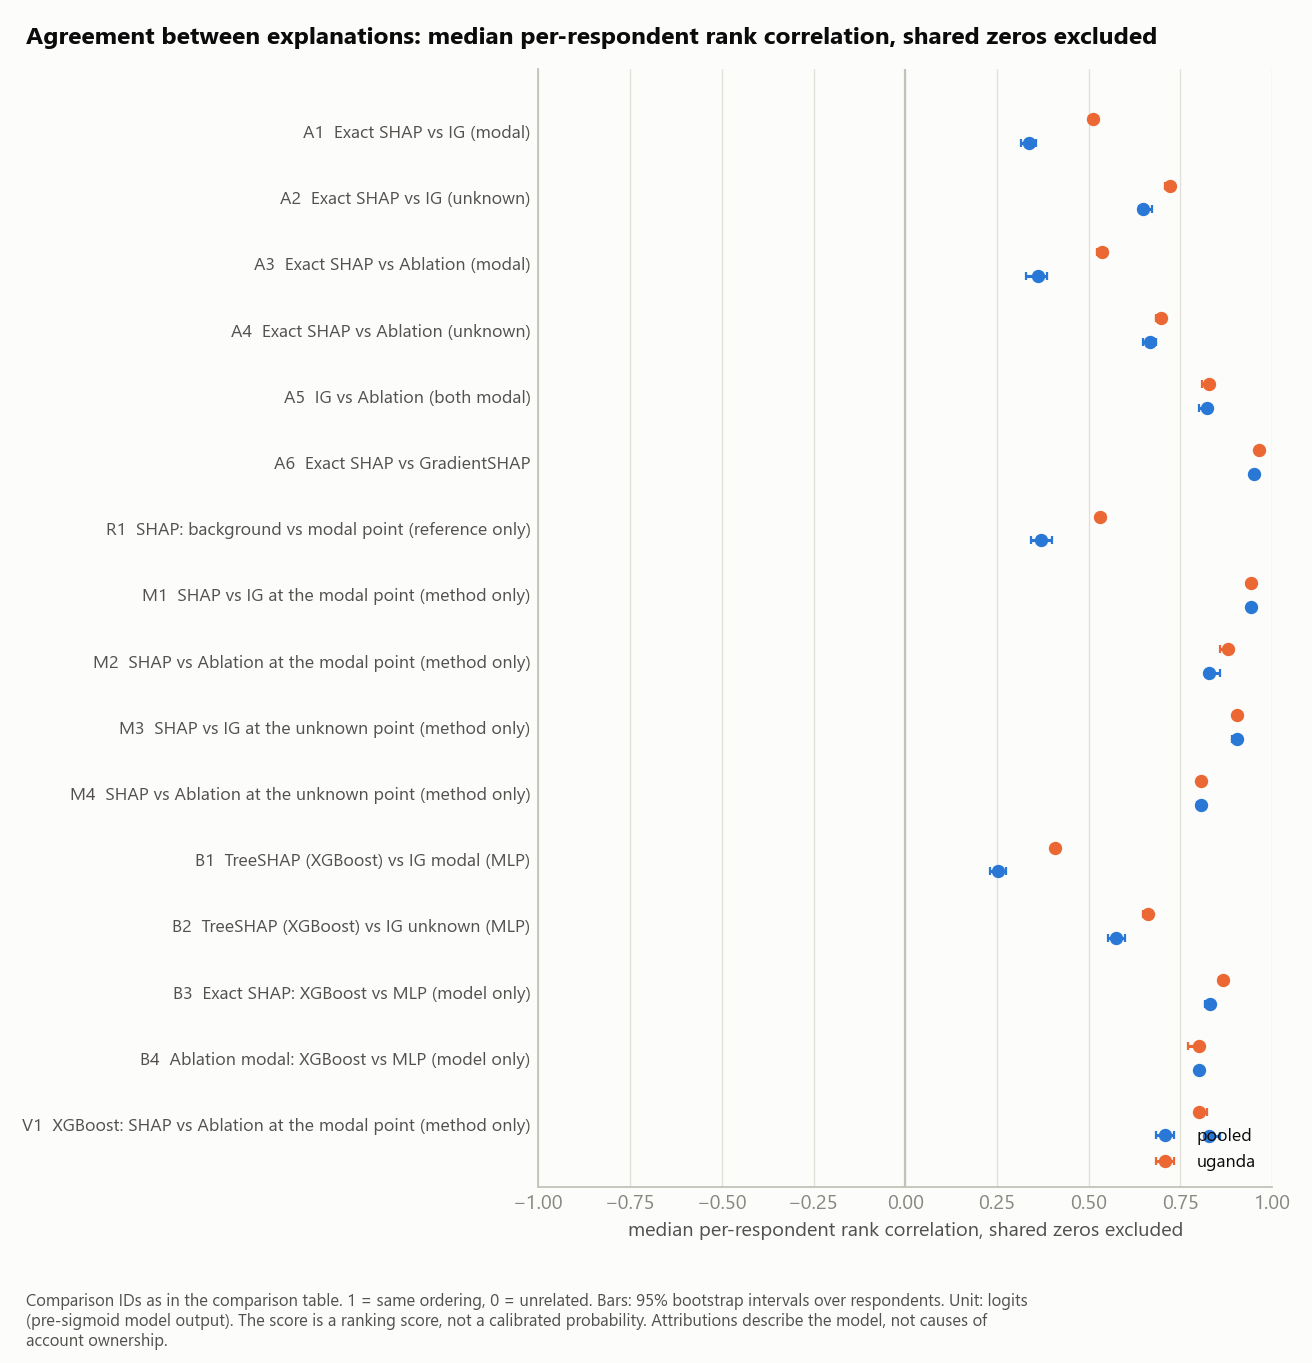

In [18]:
table = pd.read_csv(ARTIFACTS / "comparison_table.csv")
columns = ["id", "comparison", "global_spearman", "instance_spearman_median_excluding_shared_zeros",
           "instance_spearman_median_excluding_shared_zeros_ci_low", "instance_spearman_median_excluding_shared_zeros_ci_high",
           "same_top_feature_share", "sign_agreement_share"]
pivot = table[table["sample"] == "pooled"][columns].set_index("id")
pivot.columns = ["comparison", "global ρ", "per-respondent ρ", "ci low", "ci high", "same top", "same sign"]
display(pivot)
figure("comparison_forest__instance_no_shared_zeros_rank_correlation.png", width=820)

Changing only the reference (R1) produces as much disagreement as the raw SHAP-vs-Captum comparisons (A1, A3);
changing only the method (M1, M2) produces little. In experiment B, the two models explained the same way (B3) agree
closely, so the poor TreeSHAP-vs-IG agreement (B1) reflects the methods, not the models.

### Why they diverge — evidence, not stories (D6.5)

Value function: Ablation − Shapley (same reference) explained by the sum of pairwise interactions: xgboost R² 0.95, mlp R² 0.96
Correlated fields: Spearman(max Cramér's V, method disagreement) = +0.58, p = 0.08, n = 10 fields  ->  suggestive, not established
Named pairs (Cramér's V): {'relationship_with_head x marital_status': 0.3, 'country x location_type': 0.48}
Gradient saturation: median flat share of IG's path unknown 0%, modal 3%  ->  not supported


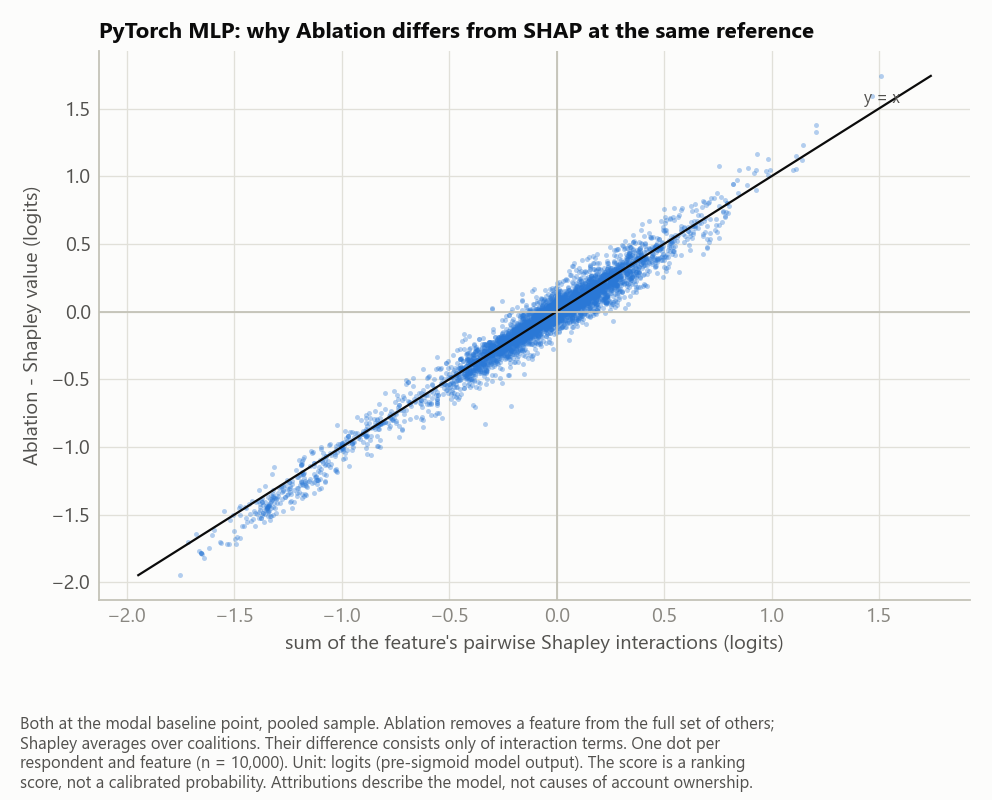

In [19]:
evidence = comparison["evidence"]
vf = evidence["value_function"]
print("Value function: Ablation − Shapley (same reference) explained by the sum of pairwise interactions: "
      + ", ".join(f"{m} R² {vf[m]['r2_gap_explained_by_pairwise_sum_identity']:.2f}" for m in vf))
cf = evidence["correlated_features"]
r = cf["spearman_max_v_vs_disagreement__methods (A1, A3, A5 mean)"]
print(f"Correlated fields: Spearman(max Cramér's V, method disagreement) = {r['rho']:+.2f}, p = {r['p_value']:.2f}, "
      f"n = {r['n_features']} fields  ->  suggestive, not established")
print("Named pairs (Cramér's V):", {k: round(v, 2) for k, v in cf["named_pairs"].items()})
gs = evidence["gradient_saturation"]
print("Gradient saturation: median flat share of IG's path "
      + ", ".join(f"{k} {v['median_flat_share_of_path']:.0%}" for k, v in gs.items()) + "  ->  not supported")
figure("comparison_value_function__mlp.png", width=640)

### Faithfulness — asking the model, not the explanations (D6.6–D6.8)

Agreement is not correctness. Deletion/insertion curves remove fields in each method's order and watch the logit;
every method beats a random order by a wide margin. Which method looks best depends on what "removing" means — the
background rows favour SHAP, the modal point favours IG and Ablation — so no single winner is declared.

,background,modal point
"MLP, pooled: deletion area (higher = more faithful)",,
exact SHAP,1.410,1.608
GradientSHAP,1.406,1.616
SHAP @ modal point,1.328,1.621
IG modal,1.316,1.610
IG unknown,1.276,1.619
Ablation modal,1.329,1.605
Ablation unknown,1.297,1.577
random order,0.911,1.048


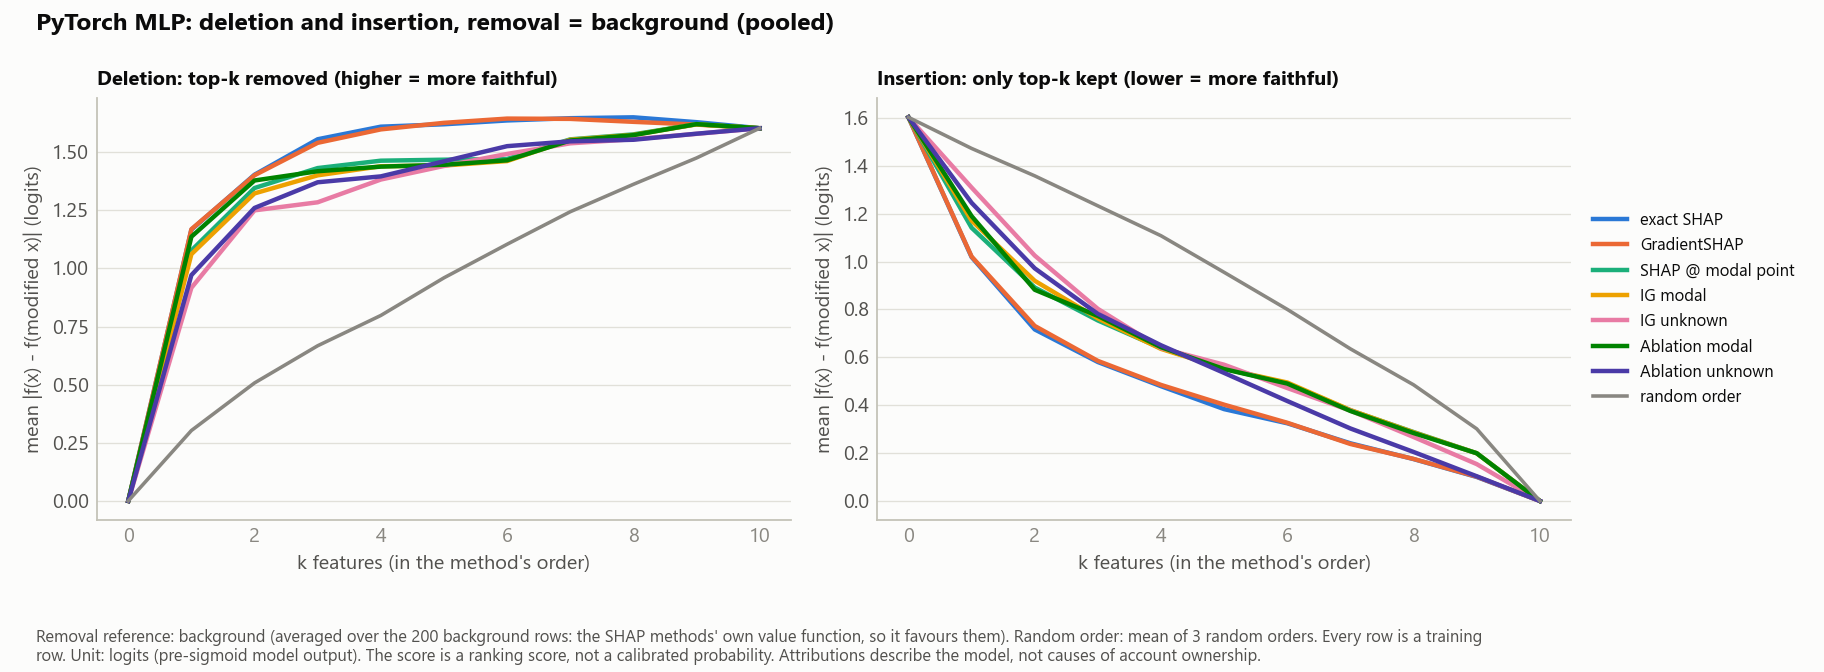

In [20]:
faith = comparison["faithfulness"]["mlp"]["pooled"]
display(pd.DataFrame({removal: {m: v["deletion_area"]["mean"] for m, v in by.items()} for removal, by in faith.items()})
        .rename_axis("MLP, pooled: deletion area (higher = more faithful)"))
figure("faithfulness_curves__mlp__background.png")

In [21]:
randomisation = comparison["randomisation"]
display(pd.DataFrame({m: e["median_instance_rank_correlation_excluding_shared_zeros"]
                      for m, e in randomisation["methods"].items()}, index=randomisation["steps"])
        .assign(**{"model logits (corr.)": randomisation["model_logit_correlation"]}))
display(pd.DataFrame(comparison["stability"]["methods"]).T[["median_relative_l1_change", "median_instance_rank_correlation"]])

,exact SHAP,IG modal,Ablation modal,model logits (corr.)
trained model,1.000,1.000,1.000,1.000
+ output layer,0.279,0.600,0.488,0.186
+ hidden layer 2,0.588,0.714,0.600,0.600
+ hidden layer 1,0.303,0.400,0.429,0.027
+ embeddings,0.103,0.486,0.396,0.133


,median_relative_l1_change,median_instance_rank_correlation
exact SHAP · xgboost,0.031,0.988
Ablation modal · xgboost,0.055,0.988
TreeSHAP · xgboost,0.031,0.988
exact SHAP · mlp,0.022,1.0
Ablation modal · mlp,0.039,1.0
IG modal · mlp,0.026,1.0


Every method's explanation degrades when the MLP's weights are scrambled (they all pass the sanity check); IG and
Ablation keep more similarity because part of their ranking is set by the baseline itself. Nudging age or household size
by one moves attributions by only a few percent.

## 7. Conclusions and limitations

* Both models rely mainly on **phone access, education and country**, and on the **country × urban/rural** interaction;
  explained the same way, they agree closely.
* SHAP and Captum agree on what matters overall but often disagree on individuals, mostly because of the **reference**,
  not the method. Any explanation shown to a decision-maker should state its reference.
* Limitations: attributions are not causal; individual explanations depend on the reference; interventional removal
  creates hybrid respondents that may not exist; there is no ground truth for explanations beyond "the Shapley value for
  this reference"; scores are uncalibrated; Uganda is small and is compared with a pooled reference; four surveys from
  2016–2018 are pooled; every explained row is a training row.

The full write-up is `reports/xai_comparison_report.md`; the interactive version is the dashboard
(`streamlit run src/fin_inclusion/dashboard/app.py`).